## Descriptive Statistical Analysis over Insurance Dataset
Insurance Dataset : https://docs.google.com/spreadsheets/d/1dAc3E4U-gBzihJ6HLM2kYVDAqQthdReg20zwwaplTW8/edit?usp=share_link

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

In [3]:
insurance = pd.read_csv("insurance_data.csv")
insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          1340 non-null   int64  
 1   PatientID      1340 non-null   int64  
 2   age            1335 non-null   float64
 3   gender         1340 non-null   object 
 4   bmi            1340 non-null   float64
 5   bloodpressure  1340 non-null   int64  
 6   diabetic       1340 non-null   object 
 7   children       1340 non-null   int64  
 8   smoker         1340 non-null   object 
 9   region         1337 non-null   object 
 10  claim          1340 non-null   float64
dtypes: float64(3), int64(4), object(4)
memory usage: 115.3+ KB


In [5]:
insurance[insurance['age'].isnull()]

,index,PatientID,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim
2,2,3,NaN,male,33.3,82,Yes,0,No,southeast,1135.94
3,3,4,NaN,male,33.7,80,No,0,No,northwest,1136.40
4,4,5,NaN,male,34.1,100,No,0,No,northwest,1137.01
5,5,6,NaN,male,34.4,96,Yes,0,No,northwest,1137.47
6,6,7,NaN,male,37.3,86,Yes,0,No,northwest,1141.45


Since the age column has 5 null values, it may be an issue and we may have to drop these 5 rows.

In [6]:
insurance.describe()

,index,PatientID,age,bmi,bloodpressure,children,claim
count,1340.000000,1340.000000,1335.000000,1340.000000,1340.000000,1340.000000,1340.000000
mean,669.500000,670.500000,38.078652,30.668955,94.157463,1.093284,13252.745642
std,386.968991,386.968991,11.102924,6.106735,11.434712,1.205334,12109.609288
min,0.000000,1.000000,18.000000,16.000000,80.000000,0.000000,1121.870000
25%,334.750000,335.750000,29.000000,26.275000,86.000000,0.000000,4719.685000
50%,669.500000,670.500000,38.000000,30.400000,92.000000,1.000000,9369.615000
75%,1004.250000,1005.250000,47.000000,34.700000,99.000000,2.000000,16604.305000
max,1339.000000,1340.000000,60.000000,53.100000,140.000000,5.000000,63770.430000


### Q-1: What is the probability distribution of age in the insurance dataset?

-- Find out using the KDE method

Text(0.5, 1.0, "Probability Density for 'Age'")

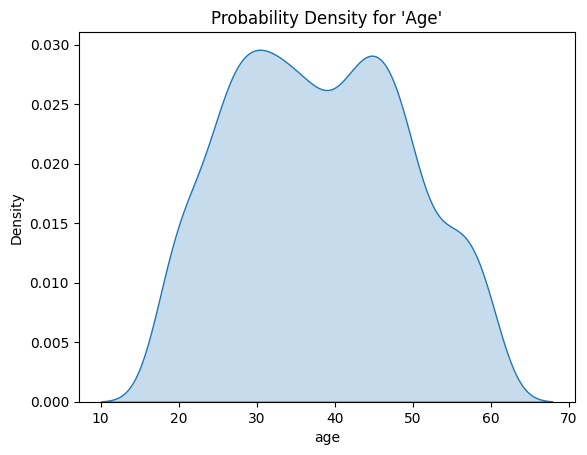

In [31]:
sns.kdeplot(data=insurance, x='age', fill=True)
plt.title("Probability Density for 'Age'")

### Q-2: What is the probability of a patient having a BMI greater than 30?

In [56]:
insurance['bmi'].mean()

np.float64(30.668955223880598)

In [ ]:
# direct approach
(insurance['bmi'] > 30).mean()

np.float64(0.5216417910447761)

In [53]:
# more explicit approach
favourable_outcome = (insurance['bmi'] > 30).sum()
total_patients = insurance['bmi'].count()
probability = favourable_outcome / total_patients
favourable_outcome, total_patients, probability

(np.int64(699), np.int64(1340), np.float64(0.5216417910447761))

<Axes: xlabel='bmi', ylabel='Density'>

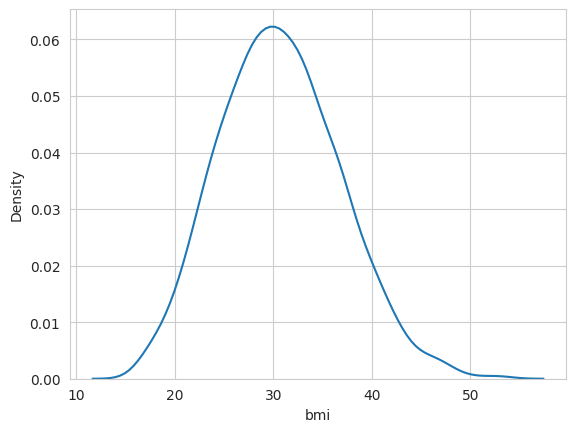

In [46]:
sns.set_style('whitegrid')
sns.kdeplot(data=insurance, x='bmi', gridsize=100)

In [55]:
insurance['bmi'].skew()

np.float64(0.28597245020808587)

Since it can be verified visually by looking at the chart and by verifying it by checking the skewness of `bmi`, it can be said that `bmi` is very close to a nomal distribution, and exhibits the properties of a normal distribution. Therefore, we can say that the probability of a perosn having a mean greater than the mean, i.e.  30, is verified to be `52%`.

This can be verified more explicitly using scipy library's defined probability function for a normal distribution:

In [58]:
probability = 1 - norm.cdf(30, 
                           loc=insurance['bmi'].mean(),
                           scale=insurance['bmi'].std())
probability

np.float64(0.5436144272589528)

### Q-3: Plot distribution plot of claim for Smoker and non smoker. What changes you see in the plot?

In [ ]:
smoker_claim = insurance[insurance['smoker'] == 'Yes']['claim']
non_smoker_claim = insurance[insurance['smoker'] == 'No']['claim']

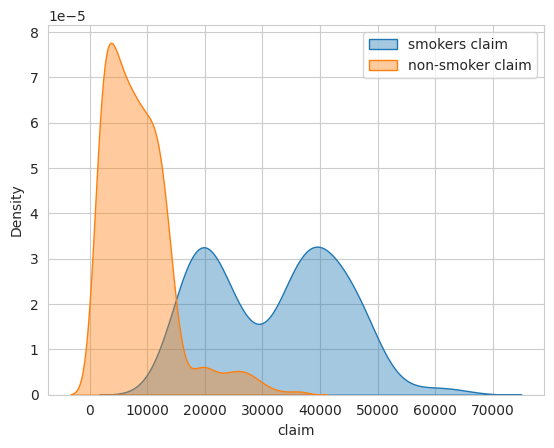

In [76]:
sns.kdeplot(data=smoker_claim, label='smokers claim', fill=True, alpha=0.4)
sns.kdeplot(data=non_smoker_claim, label='non-smoker claim', fill=True, alpha=0.4)
plt.legend()
plt.show()

#### Observations and relative changes in the curves of Smoker and Non-Smoker
- For some reason, both the curve's maximum value is crossing 1 even though its a kdeplot.
- **Smoker's** claim is *Multimodal*, while **Non-Smoker's** claim is *Unimodal*.
- The claim for **Non-Smokers** remain very low, while **Smokers** have usually claimed relatively higher amounts.

<Axes: xlabel='claim', ylabel='Density'>

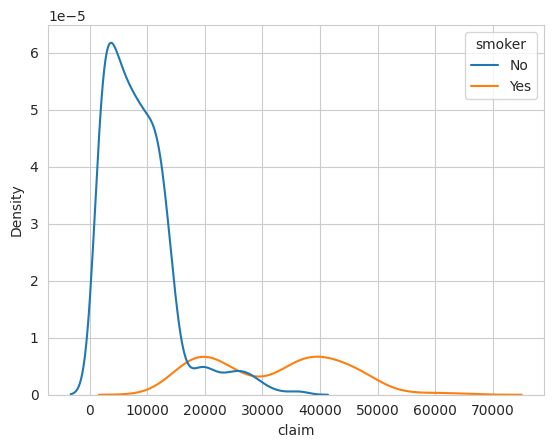

In [ ]:
# this graph represent the curves proportionally, while the graph above does not.
sns.kdeplot(data=insurance, x='claim', hue='smoker')

### Q-4: Plot the 2D probability density plot of claim and age in the insurance dataset?

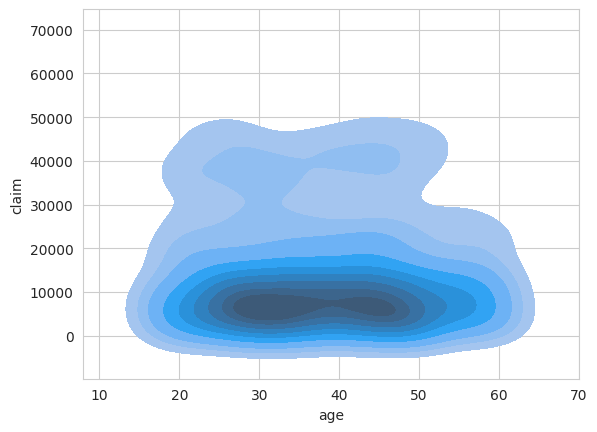

In [78]:
sns.kdeplot(data=insurance, x='age', y='claim', fill=True)
plt.show()

The relation beween `claim` and `age` seems to be *multimodal* as well. People around the age group of 25-48 have mostly claimed 5000-8000.

### Q-5: How does the distribution of claim changes for different region? Plot density plot and note down the observations

In [79]:
insurance['region'].value_counts()

region
southeast    443
northwest    349
southwest    314
northeast    231
Name: count, dtype: int64

<Axes: xlabel='claim', ylabel='Density'>

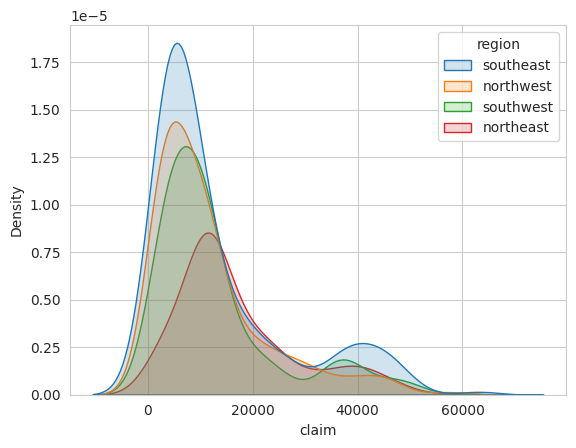

In [107]:
sns.kdeplot(insurance, x='claim', hue='region', fill=True, alpha=0.2)

#### Observations
- Approximate claim in all the region approximately lies somewhere around 10000. Although, its still bimodal.
- All regions follow the same trends for claims, the highest claim being around 6000-10000.

### Q6: Plot PDF and CDF of claim in insurance data

<Axes: xlabel='claim', ylabel='Density'>

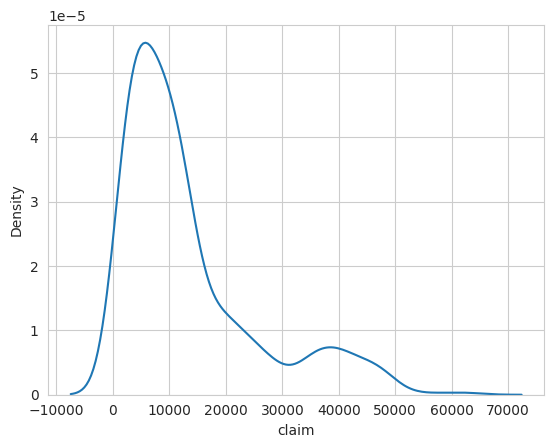

In [84]:
sns.kdeplot(data=insurance, x='claim')

<Axes: xlabel='claim', ylabel='Proportion'>

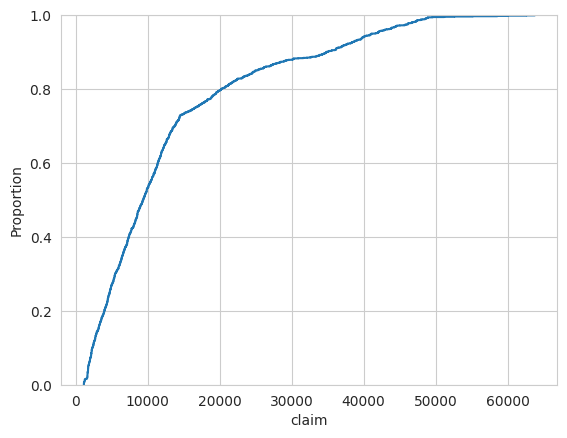

In [83]:
sns.ecdfplot(data=insurance, x='claim')

### Q-7: Given a probability density function f(x) = 2x for 0 <= x <= 1 and f(x) = 0 otherwise, compute the cumulative distribution function F(x) and plot it. Use this to find the probability that X is greater than 0.5.

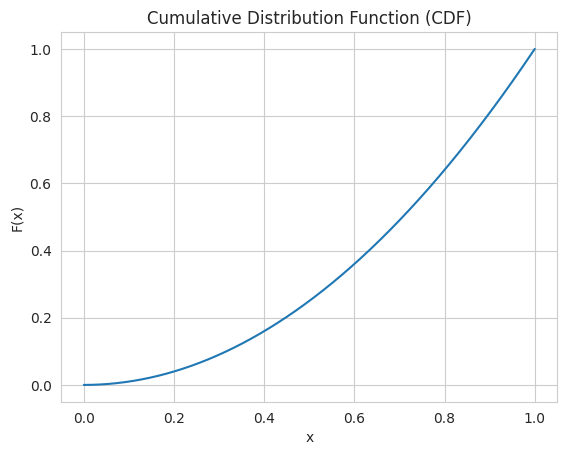

Probability that X is greater than 0.5: 0.75


In [108]:
def pdf(x):
  if 0 <= x <= 1:
    return 2 * x
  else:
    return 0

def cdf(x):
  if x < 0:
    return 0
  elif 0 <= x <= 1:
    return x ** 2
  else:
    return 1

# Generate a range of x values from 0 to 1
x = np.linspace(0, 1, 10000)

# Calculate the corresponding CDF values
y_cdf = np.array([cdf(xi) for xi in x])

# Plot the CDF
plt.plot(x, y_cdf)
plt.xlabel('x')
plt.ylabel('F(x)')
plt.title('Cumulative Distribution Function (CDF)')
plt.grid(True)
plt.show()

# Calculate the probability that X is greater than 0.5
p_x_gt_0_5 = 1 - cdf(0.5)
print("Probability that X is greater than 0.5:", p_x_gt_0_5)

### Q-8: In a manufacturing process, the thickness of a certain material is known to be normally distributed with a mean of 1.2 mm and a standard deviation of 0.05 mm. What is the probability density function of the thickness? Plot the PDF and use it to compute the probability that the thickness is between 1.1 mm and 1.3 mm.

In [86]:
mean = 1.2
std = 0.05

np.random.seed(42)
samples = np.random.normal(loc=mean, scale=std, size=10000)
samples

array([1.22483571, 1.19308678, 1.23238443, ..., 1.16473416, 1.22478828,
       1.23221942], shape=(10000,))

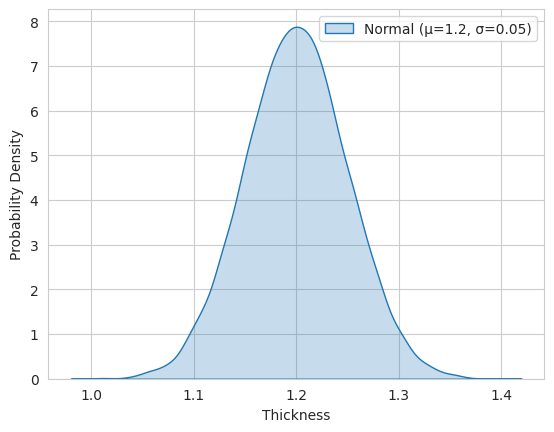

In [89]:
sns.kdeplot(data=samples, fill=True, label=f"Normal (μ={mean}, σ={std})")
plt.xlabel('Thickness')
plt.ylabel("Probability Density")
plt.legend()
plt.show()

Upon visual observation, the probabiliy of the thickness being between 1.1 to 1.3 mm seems to be 0.95 or 95% as per the empirical rules.

In [96]:
favourable = np.sum((samples >= 1.1) & (samples <= 1.3))
total = np.count_nonzero(samples)
print(f"Probability of the thickness lying between 1.1-1.3 mm is {favourable/total}")

Probability of the thickness lying between 1.1-1.3 mm is 0.9533


Our observation has been verified by hardcoded calculation.

### Q-9 : A data scientist is investigating the distribution of customer ages in a retail store. She collects a sample of 100 ages and estimates the probability density function using kernel density estimation. What bandwidth should she choose to obtain the best estimate?

Choosing the best bandwidth for KDE involves finding a balance between overfitting and underfitting. If the bandwidth is too small, the estimated PDF may have a lot of small, spurious oscillations or noise, which may not accurately represent the underlying distribution of the data. On the other hand, if the bandwidth is too large, the estimated PDF may be overly smooth and may not capture the finer details or variations in the data.

There are several methods that can be used to select the optimal bandwidth for KDE, including cross-validation, rule-of-thumb methods (e.g., Scott's rule, Silverman's rule), and optimization techniques (e.g., maximum likelihood estimation).

One common rule-of-thumb method for choosing the bandwidth in KDE is Scott's rule, which is given by:

`h = 1.06 * sigma * n^(-1/5)`

where `h` is the bandwidth, sigma is the standard deviation of the data, and `n` is the number of data points in the sample. Scott's rule is often used as a default bandwidth choice in many KDE implementations.

In [109]:
# Cross validation approach
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KernelDensity

# Generate a sample of 100 ages
ages = np.random.normal(loc=40, scale=10, size=100)

# Define the range of bandwidths to test
bandwidths = 10 ** np.linspace(-1, 1, 100)

# Define the parameters for the kernel density estimator
params = {'bandwidth': bandwidths, 'kernel': ['gaussian']}

# Create a GridSearchCV object to find the best bandwidth
grid = GridSearchCV(KernelDensity(), params, cv=5)
grid.fit(ages.reshape(-1, 1))

# Extract the best bandwidth from the GridSearchCV object
best_bandwidth = grid.best_estimator_.bandwidth
print('Best bandwidth:', best_bandwidth)

Best bandwidth: 4.5348785081285845


In [110]:
# Scott rule bandwidth
# h = 1.06 * sigma * n^(-1/5)
h = 1.06 * 10 * (100**(-1/5))
print("Scott rule bandwidth:", h)

Scott rule bandwidth: 4.219936007867071
